In [15]:
import pandas as pd

data = [
 
    ("마파두부덮밥", "Mapo tofu rice bowl", "Caution"),
    ("계란파국", "Egg scallion soup", "Safe"),
    ("만두찜", "Steamed dumplings", "Caution"),
    ("단무지", "Pickled radish", "Safe"),
    ("참깨샐러드", "Sesame salad", "Safe"),
    ("배추김치", "Napa cabbage kimchi", "Safe"),
    ("요구르트", "Yogurt", "Safe"),
    ("흑미밥", "Black rice", "Safe"),
    ("보리새우매운탕", "Spicy dried shrimp stew", "Safe"),
    ("궁중떡볶이", "Royal-style tteokbokki", "Safe"),
    ("감자조림", "Braised potatoes", "Safe"),
    ("청포묵김가루무침", "Mung bean jelly salad", "Safe"),
    ("매실차", "Plum tea", "Safe"),
    ("현미밥", "Brown rice", "Safe"),
    ("순두부찌개", "Soft tofu stew", "Safe"),
    ("돈육메추리알장조림", "Braised pork with quail eggs", "Unsafe"),
    ("가지나물", "Seasoned eggplant", "Safe"),
    ("콘참치팬네샐러드", "Corn tuna penne salad", "Safe"),


]

df = pd.DataFrame(data, columns=["dish_kr", "dish_en", "label"])
df.head(10)

,dish_kr,dish_en,label
0,마파두부덮밥,Mapo tofu rice bowl,Caution
1,계란파국,Egg scallion soup,Safe
2,만두찜,Steamed dumplings,Caution
3,단무지,Pickled radish,Safe
4,참깨샐러드,Sesame salad,Safe
5,배추김치,Napa cabbage kimchi,Safe
6,요구르트,Yogurt,Safe
7,흑미밥,Black rice,Safe
8,보리새우매운탕,Spicy dried shrimp stew,Safe
9,궁중떡볶이,Royal-style tteokbokki,Safe


In [16]:
df["label"].value_counts()

label
Safe       15
Caution     2
Unsafe      1
Name: count, dtype: int64

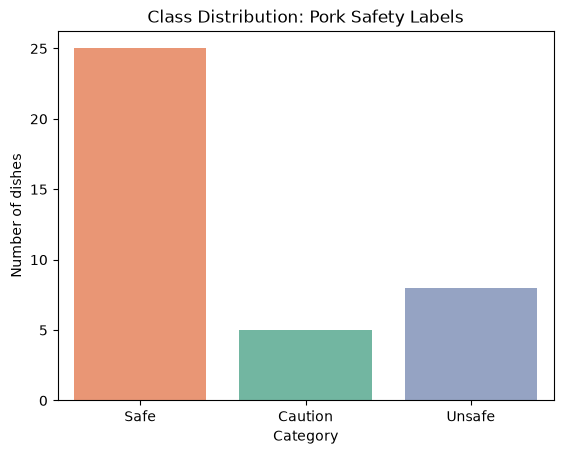

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="label", order=["Safe", "Caution", "Unsafe"], 
              hue="label", palette="Set2", legend=False)
plt.title("Class Distribution: Pork Safety Labels")
plt.xlabel("Category")
plt.ylabel("Number of dishes")
plt.show()

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3))
X = vectorizer.fit_transform(df["dish_kr"])
y = df["label"]

print("Feature matrix shape:", X.shape)

Feature matrix shape: (18, 181)


In [6]:
from sklearn import set_config
set_config(display='text')
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

model = LogisticRegression(max_iter=1000, class_weight="balanced")
model.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [14]:
from sklearn.metrics import classification_report, f1_score

y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred))
print("Macro F1-Score:", f1_score(y_test, y_pred, average="macro"))

              precision    recall  f1-score   support

     Caution       0.00      0.00      0.00         1
        Safe       0.70      1.00      0.82         7
      Unsafe       0.00      0.00      0.00         2

    accuracy                           0.70        10
   macro avg       0.23      0.33      0.27        10
weighted avg       0.49      0.70      0.58        10

Macro F1-Score: 0.2745098039215686


C:\Users\nila\anaconda3\envs\my_ml_env\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\nila\anaconda3\envs\my_ml_env\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\nila\anaconda3\envs\my_ml_env\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", res

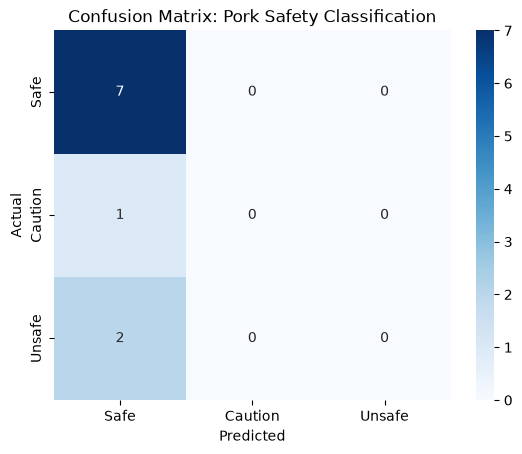

In [8]:
from sklearn.metrics import confusion_matrix

labels_order = ["Safe", "Caution", "Unsafe"]
cm = confusion_matrix(y_test, y_pred, labels=labels_order)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels_order, yticklabels=labels_order)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix: Pork Safety Classification")
plt.show()

In [9]:
new_dishes = ["돼지불고기", "미역국", "훈제오리", "감자탕"]
new_X = vectorizer.transform(new_dishes)
predictions = model.predict(new_X)

for dish, pred in zip(new_dishes, predictions):
    print(f"{dish} → {pred}")

돼지불고기 → Unsafe
미역국 → Safe
훈제오리 → Safe
감자탕 → Safe


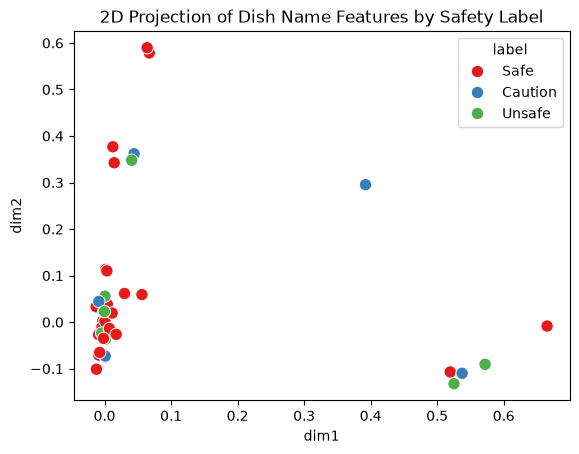

In [10]:
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(n_components=2, random_state=42)
X_2d = svd.fit_transform(X)

plot_df = pd.DataFrame(X_2d, columns=["dim1", "dim2"])
plot_df["label"] = y.values

sns.scatterplot(data=plot_df, x="dim1", y="dim2", hue="label",
                 hue_order=["Safe", "Caution", "Unsafe"], palette="Set1", s=80)
plt.title("2D Projection of Dish Name Features by Safety Label")
plt.show()